In [1]:
# ==========================================================
#                   Universidad Franz Tamayo
# ----------------------------------------------------------
#                        MINERIA DE DATOS
# ----------------------------------------------------------
#        Enrique Alejandro Laurel Cossio, 2026
# ==========================================================
#  Clase: K-Means Clustering - Segmentación de Clientes iFood
# ==========================================================

# 🍔 K-Means Clustering: Segmentación de Clientes iFood
## Universidad Franz Tamayo — Minería de Datos
### Docente: Enrique Alejandro Laurel Cossio | 2026

---

## 🎯 Objetivos de la Clase

Al finalizar esta clase, el estudiante será capaz de:

1. ✅ **Comprender** la diferencia entre aprendizaje supervisado y no supervisado
2. ✅ **Explicar** el algoritmo K-Means paso a paso
3. ✅ **Implementar** K-Means en Python usando scikit-learn
4. ✅ **Interpretar** y perfilar los clusters resultantes
5. ✅ **Evaluar** la calidad del modelo con métricas apropiadas

---

## ⏱️ Plan de Clase (80 minutos)

| Sección | Tema | Tiempo |
|---|---|---|
| 1 | Marco Teórico | 15 min |
| 2 | Actividad Participativa 1 | 5 min |
| 3 | Exploración del Dataset | 10 min |
| 4 | Preprocesamiento | 10 min |
| 5 | Implementación K-Means | 15 min |
| 6 | Actividad Participativa 2 | 10 min |
| 7 | Evaluación y Métricas | 5 min |
| 8 | Conclusiones | 5 min |

---

> 💡 **Dataset**: Datos de marketing de iFood — una empresa de delivery de comida de Brasil. Analizaremos el comportamiento de compra de sus clientes para segmentarlos en grupos estratégicos.


---
# 📚 PARTE 1: Marco Teórico
## ⏱️ (15 minutos)

---

## 🤖 ¿Qué es el Aprendizaje de Máquina?

El Machine Learning se divide en dos grandes paradigmas:

### 🏫 Aprendizaje SUPERVISADO
- El modelo aprende a partir de **datos etiquetados** (con respuesta correcta)
- Ejemplo: predecir si un cliente comprará o no (hay una columna `compró = Sí/No`)
- Algoritmos: Regresión Lineal, Árbol de Decisión, SVM, Random Forest

### 🔍 Aprendizaje NO SUPERVISADO
- El modelo **descubre patrones ocultos** sin etiquetas previas
- Ejemplo: agrupar clientes similares **sin saber de antemano** cuántos tipos hay
- Algoritmos: **K-Means**, DBSCAN, Clustering Jerárquico, PCA

```
SUPERVISADO          NO SUPERVISADO
───────────          ──────────────
Datos + Etiquetas    Solo Datos
      │                    │
   Modelo              Modelo
      │                    │
  Predicción           Patrones/Grupos
```

> 📌 **Hoy trabajamos con aprendizaje NO SUPERVISADO** — específicamente con el algoritmo K-Means para agrupar clientes de iFood.


## 🗂️ ¿Qué es el Clustering (Agrupamiento)?

El **clustering** es el proceso de dividir un conjunto de datos en grupos (clusters) de manera que:
- Los elementos **dentro** de un grupo son lo más **similares** posible entre sí
- Los elementos **entre** grupos son lo más **diferentes** posible

### 🌍 Aplicaciones Reales

| Industria | Aplicación |
|---|---|
| 🛒 E-commerce | Segmentación de clientes por comportamiento de compra |
| 🏥 Medicina | Clasificación de tipos de enfermedades o pacientes |
| 📱 Redes Sociales | Detección de comunidades de usuarios |
| 🏦 Finanzas | Detección de fraude, perfiles de riesgo |
| 📰 Noticias | Agrupación de artículos por temática |
| 🎵 Música | Recomendación por géneros o estilos |

---

## ⚙️ El Algoritmo K-Means paso a paso

### 🎯 Idea Central
Dado un conjunto de datos y un número **K** de grupos deseados, K-Means encuentra K **centroides** (centros de grupos) que minimizan la distancia total de cada punto a su centroide más cercano.

### 🔄 Pasos del Algoritmo

**1. 🎯 Inicialización**
- Se eligen **K centroides iniciales** de forma aleatoria (o con K-Means++)
- Estos son los "centros" provisionales de los clusters

**2. 📏 Asignación**
- Cada punto de datos se asigna al **centroide más cercano**
- La distancia se mide con la **distancia euclidiana**

**3. 🔄 Actualización**
- Se **recalcula** el centroide de cada cluster como el **promedio** de todos sus puntos
- Los centroides se mueven hacia el centro real de su grupo

**4. ✅ Convergencia**
- Se repiten los pasos 2 y 3 hasta que los centroides **ya no cambien** (o el cambio sea mínimo)

```
INICIO
  │
  ▼
🎯 Elige K centroides aleatorios
  │
  ▼
📏 Asigna cada punto al centroide más cercano
  │
  ▼
🔄 Recalcula centroides (promedio de cada cluster)
  │
  ├──► ¿Centroides cambiaron? ──► SÍ ──► Volver a 📏
  │
  └──► NO
       │
       ▼
     ✅ FIN — Clusters encontrados
```


## 📐 Fundamento Matemático

### Distancia Euclidiana
La similitud entre dos puntos se mide con la distancia euclidiana. Para dos puntos $p$ y $q$ en un espacio de $n$ dimensiones:

$$d(p, q) = \sqrt{\sum_{i=1}^{n}(p_i - q_i)^2}$$

**Ejemplo en 2D** (Income vs TotalSpent):
$$d = \sqrt{(Income_1 - Income_2)^2 + (Spent_1 - Spent_2)^2}$$

---

### Función Objetivo — WCSS
K-Means minimiza la **Suma de Cuadrados Intra-Cluster** (Within-Cluster Sum of Squares):

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

Donde:
- $K$ = número de clusters
- $C_k$ = conjunto de puntos en el cluster $k$
- $\mu_k$ = centroide del cluster $k$
- $\|x_i - \mu_k\|^2$ = distancia cuadrada del punto $x_i$ a su centroide

> 📌 **Menor WCSS = Clusters más compactos = Mejor modelo**

---

## ⚖️ Ventajas y Desventajas de K-Means

| ✅ Ventajas | ❌ Desventajas |
|---|---|
| Simple e intuitivo | Hay que especificar K de antemano |
| Escalable a grandes datasets | Sensible a outliers |
| Rápido y eficiente | Solo detecta clusters esféricos |
| Fácil de interpretar | Resultado puede variar (aleatorio) |
| Ampliamente soportado | No maneja bien distintas densidades |

---

## 🔄 Comparativa con Otros Algoritmos

| Característica | K-Means | DBSCAN | Jerárquico |
|---|---|---|---|
| ¿Requiere K? | ✅ Sí | ❌ No | ❌ No |
| Forma de clusters | Esférica | Cualquiera | Cualquiera |
| Maneja outliers | ❌ No | ✅ Sí | Parcial |
| Escalabilidad | ✅ Alta | Media | ❌ Baja |
| Interpretabilidad | ✅ Alta | Media | ✅ Alta |
| Velocidad | ✅ Rápido | Medio | ❌ Lento |


---
# 🧠 ACTIVIDAD PARTICIPATIVA 1: Reflexión Conceptual
## ⏱️ (5 minutos)

---

## 🧠 ACTIVIDAD 1: Reflexión Conceptual (5 minutos)

> 📝 **Instrucciones**: Haz doble clic en esta celda para editarla y responde las siguientes preguntas. Luego presiona `Shift + Enter` para confirmar.

---

**1.** Imagina que tienes 1000 clientes de un restaurante de comida a domicilio. ¿Cómo los agruparías manualmente? ¿Qué criterios usarías?

> **✏️ Tu respuesta**: _____

---

**2.** Mirando las columnas del dataset iFood (`Income`, `MntWines`, `MntMeatProducts`, `Kidhome`, `Teenhome`, `NumWebPurchases`...), ¿cuántos grupos de clientes crees que existen? ¿Por qué?

> **✏️ Tu respuesta**: _____

---

**3.** ¿Qué columnas del dataset crees que son más útiles para agrupar clientes? ¿Por qué esas y no otras?

> **✏️ Tu respuesta**: _____

---

**4.** ¿Por qué crees que es importante para iFood conocer los distintos tipos de clientes?

> **✏️ Tu respuesta**: _____

---

> 🎙️ **El docente pedirá a algunos estudiantes compartir sus respuestas con la clase**


---
# 💻 PARTE 2: Implementación en Python
---

## 📦 Paso 0: Importación de Librerías
### ⏱️ (Exploración del Dataset: 10 min)

Comenzamos importando todas las librerías necesarias para nuestro análisis:

| Librería | Uso |
|---|---|
| `pandas` | Manipulación de datos en tablas (DataFrames) |
| `numpy` | Operaciones numéricas y matemáticas |
| `matplotlib` | Gráficos y visualizaciones base |
| `seaborn` | Visualizaciones estadísticas más elegantes |
| `sklearn.cluster.KMeans` | El algoritmo K-Means |
| `sklearn.preprocessing.StandardScaler` | Normalización de datos |
| `sklearn.metrics.silhouette_score` | Métrica de calidad del clustering |


In [3]:
# ── Librerías de manipulación de datos ──────────────────────
import pandas as pd
import numpy as np

# ── Librerías de visualización ───────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Librerías de Machine Learning ────────────────────────────
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ── Configuración de estilo ──────────────────────────────────
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("✅ Librerías cargadas correctamente")
print(f"   pandas  {pd.__version__}")
print(f"   numpy   {np.__version__}")

✅ Librerías cargadas correctamente
   pandas  2.3.2
   numpy   2.3.3


---
## 📂 Paso 1: Carga y Primera Inspección del Dataset

El dataset de **iFood** contiene información de clientes de una plataforma de delivery de comida brasileña. Incluye datos demográficos, hábitos de compra y respuesta a campañas de marketing.


In [4]:
# ── Cargar el dataset ────────────────────────────────────────
# Ruta relativa: el notebook está en notebooks_datasets/
# y el CSV está en notebooks_datasets/data/
df = pd.read_csv('data/ifood.csv')

print("📊 Dataset cargado exitosamente")
print(f"   Filas    : {df.shape[0]:,}")
print(f"   Columnas : {df.shape[1]}")
print()
print("🔍 Primeras 5 filas:")
df.head()

📊 Dataset cargado exitosamente
   Filas    : 2,240
   Columnas : 29

🔍 Primeras 5 filas:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
# ── Información general del DataFrame ───────────────────────
print("📋 Información del dataset:")
df.info()

📋 Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPur

In [6]:
# ── Estadísticas descriptivas ────────────────────────────────
print("📈 Estadísticas descriptivas:")
df.describe().round(2)

📈 Estadísticas descriptivas:


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.00,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,...,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.0,2240.0,2240.00
mean,5592.16,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,...,5.32,0.07,0.07,0.07,0.06,0.01,0.01,3.0,11.0,0.15
std,3246.66,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,...,2.43,0.26,0.26,0.26,0.25,0.11,0.10,0.0,0.0,0.36
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
25%,2828.25,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,...,6.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
75%,8427.75,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,...,7.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,...,20.00,1.00,1.00,1.00,1.00,1.00,1.00,3.0,11.0,1.00


In [7]:
# ── Valores nulos ────────────────────────────────────────────
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)

resumen_nulos = pd.DataFrame({
    'Nulos': nulos,
    'Porcentaje (%)': nulos_pct
})

# Solo mostrar columnas que tienen nulos
resumen_nulos_filtrado = resumen_nulos[resumen_nulos['Nulos'] > 0]

if resumen_nulos_filtrado.empty:
    print("✅ No hay valores nulos en el dataset")
else:
    print("⚠️  Columnas con valores nulos:")
    print(resumen_nulos_filtrado)

⚠️  Columnas con valores nulos:
        Nulos  Porcentaje (%)
Income     24            1.07


---
## 🛠️ Paso 2: Ingeniería de Features

Antes de explorar los datos, creamos algunas variables derivadas que nos darán información más rica sobre los clientes. Esto se llama **Feature Engineering** (Ingeniería de Características).

### Variables que crearemos:
- **`Age`**: Edad del cliente (2024 - Año de nacimiento)
- **`TotalSpent`**: Gasto total en todos los productos de iFood
- **`TotalPurchases`**: Número total de compras realizadas


In [8]:
# ── Feature Engineering ──────────────────────────────────────

# Edad del cliente
df['Age'] = 2026 - df['Year_Birth']

# Gasto total en todos los productos
columnas_gasto = ['MntWines', 'MntFruits', 'MntMeatProducts',
                  'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['TotalSpent'] = df[columnas_gasto].sum(axis=1)

# Total de compras por todos los canales
columnas_compras = ['NumDealsPurchases', 'NumWebPurchases',
                    'NumCatalogPurchases', 'NumStorePurchases']
df['TotalPurchases'] = df[columnas_compras].sum(axis=1)

print("✅ Features creados:")
print(f"   Age          → min: {df['Age'].min()}, max: {df['Age'].max()}")
print(f"   TotalSpent   → min: {df['TotalSpent'].min()}, max: {df['TotalSpent'].max()}")
print(f"   TotalPurchases → min: {df['TotalPurchases'].min()}, max: {df['TotalPurchases'].max()}")

# Vista de las nuevas columnas
df[['ID', 'Age', 'Income', 'TotalSpent', 'TotalPurchases']].head()

✅ Features creados:
   Age          → min: 30, max: 133
   TotalSpent   → min: 5, max: 2525
   TotalPurchases → min: 0, max: 44


,ID,Age,Income,TotalSpent,TotalPurchases
0,5524,69,58138.0,1617,25
1,2174,72,46344.0,27,6
2,4141,61,71613.0,776,21
3,6182,42,26646.0,53,8
4,5324,45,58293.0,422,19


---
## 📊 Paso 3: Visualización Exploratoria

Antes de aplicar K-Means, es fundamental **explorar y entender los datos**. Las visualizaciones nos ayudan a detectar distribuciones, outliers y relaciones entre variables.


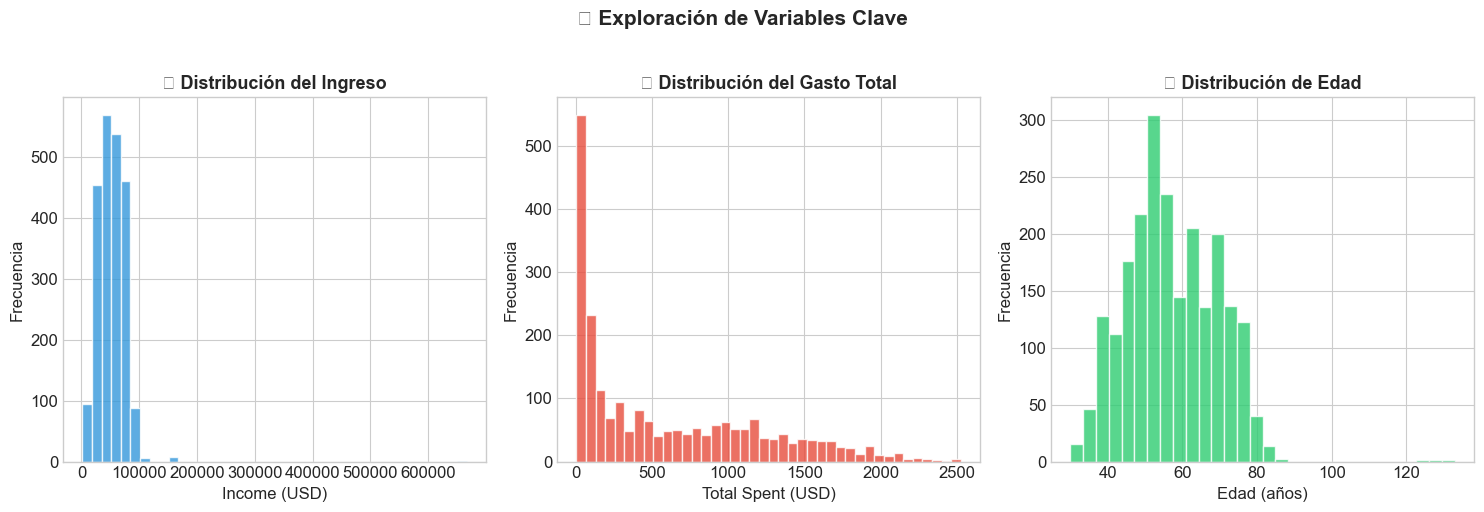

In [9]:
# ── Histogramas de las variables principales ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Distribución de Income
axes[0].hist(df['Income'].dropna(), bins=40, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].set_title('💰 Distribución del Ingreso', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Income (USD)')
axes[0].set_ylabel('Frecuencia')

# Distribución de TotalSpent
axes[1].hist(df['TotalSpent'], bins=40, color='#e74c3c', edgecolor='white', alpha=0.8)
axes[1].set_title('🛒 Distribución del Gasto Total', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Spent (USD)')
axes[1].set_ylabel('Frecuencia')

# Distribución de Age
axes[2].hist(df['Age'], bins=30, color='#2ecc71', edgecolor='white', alpha=0.8)
axes[2].set_title('👤 Distribución de Edad', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Edad (años)')
axes[2].set_ylabel('Frecuencia')

plt.suptitle('📊 Exploración de Variables Clave', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

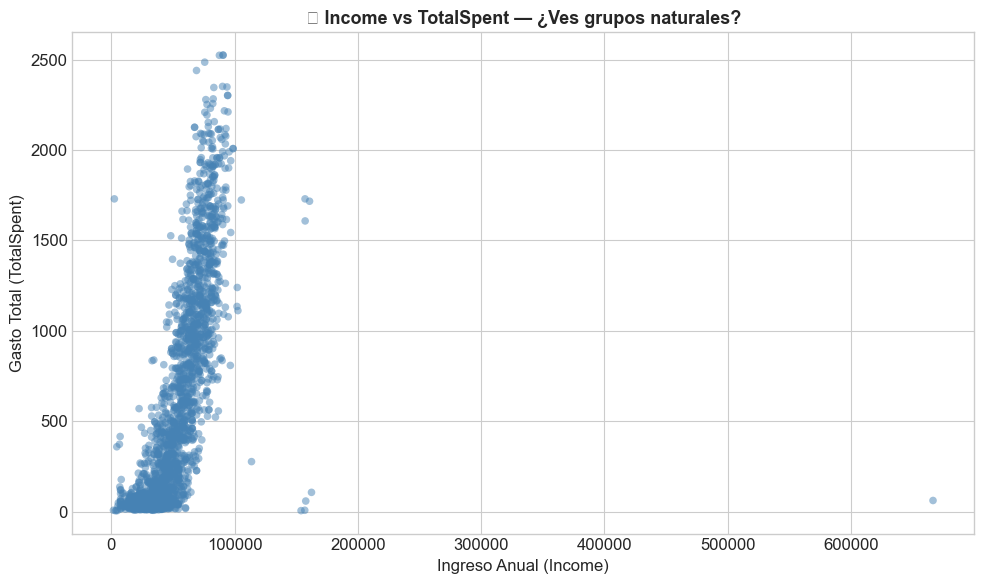

💡 Observa: ¿Puedes identificar grupos naturales en este scatter plot?


In [10]:
# ── Scatter: Income vs TotalSpent ────────────────────────────
# Este gráfico nos da una pista de cómo podrían formarse los clusters
plt.figure(figsize=(10, 6))
plt.scatter(df['Income'], df['TotalSpent'],
            alpha=0.5, c='steelblue', edgecolors='none', s=30)
plt.title('🔍 Income vs TotalSpent — ¿Ves grupos naturales?',
          fontsize=13, fontweight='bold')
plt.xlabel('Ingreso Anual (Income)')
plt.ylabel('Gasto Total (TotalSpent)')
plt.tight_layout()
plt.show()

print("💡 Observa: ¿Puedes identificar grupos naturales en este scatter plot?")

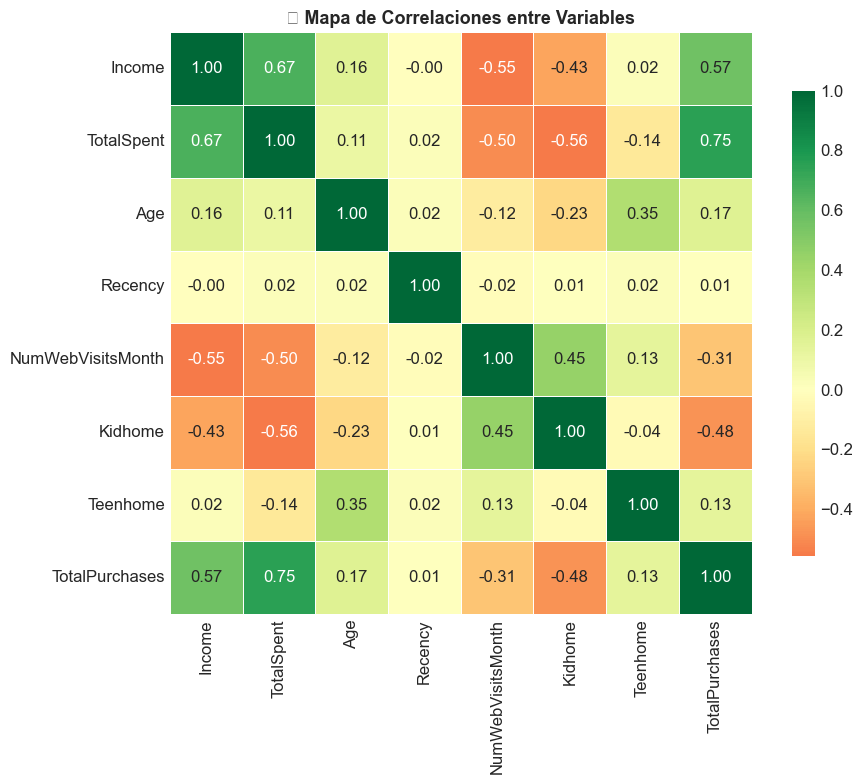

💡 Valores cercanos a 1.0 (verde): correlación positiva fuerte
💡 Valores cercanos a -1.0 (rojo): correlación negativa fuerte


In [11]:
# ── Heatmap de correlaciones ─────────────────────────────────
# Variables numéricas relevantes para el análisis
vars_correlacion = ['Income', 'TotalSpent', 'Age', 'Recency',
                    'NumWebVisitsMonth', 'Kidhome', 'Teenhome',
                    'TotalPurchases']

plt.figure(figsize=(10, 8))
corr_matrix = df[vars_correlacion].corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={'shrink': 0.8})

plt.title('🔥 Mapa de Correlaciones entre Variables',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Valores cercanos a 1.0 (verde): correlación positiva fuerte")
print("💡 Valores cercanos a -1.0 (rojo): correlación negativa fuerte")

---
## 🔧 PARTE 3: Preprocesamiento
### ⏱️ (10 minutos)

---

## ¿Por qué necesitamos preprocesar?

K-Means usa **distancias** para agrupar los datos. Si una variable tiene valores en miles (como `Income`: 30,000 - 120,000) y otra en unidades pequeñas (como `Kidhome`: 0-2), la primera dominaría las distancias y haría que el clustering sea **injusto**.

### La solución: StandardScaler
**StandardScaler** transforma cada variable para que tenga:
- **Media = 0**
- **Desviación estándar = 1**

$$z = \frac{x - \mu}{\sigma}$$

Esto pone **todas las variables en la misma escala** y garantiza que K-Means las trate con igual importancia.

### Features seleccionados para clustering:
| Variable | Justificación |
|---|---|
| `Income` | Capacidad económica del cliente |
| `TotalSpent` | Comportamiento de gasto |
| `Age` | Perfil demográfico |
| `Recency` | Cuántos días desde la última compra |
| `NumWebVisitsMonth` | Engagement digital |
| `Kidhome` | Estructura familiar |
| `Teenhome` | Estructura familiar |


In [12]:
# ── Selección de features para clustering ────────────────────
features = ['Income', 'TotalSpent', 'Age', 'Recency',
            'NumWebVisitsMonth', 'Kidhome', 'Teenhome']

# Crear subconjunto y eliminar filas con nulos
df_cluster = df[features + ['ID']].dropna()
print(f"✅ Datos para clustering: {df_cluster.shape[0]:,} registros")
print(f"   Filas eliminadas por nulos: {len(df) - len(df_cluster)}")

# Extraer solo las features numéricas
X = df_cluster[features].copy()
X.describe().round(2)

✅ Datos para clustering: 2,216 registros
   Filas eliminadas por nulos: 24


,Income,TotalSpent,Age,Recency,NumWebVisitsMonth,Kidhome,Teenhome
count,2216.00,2216.00,2216.00,2216.00,2216.00,2216.00,2216.00
mean,52247.25,607.08,57.18,49.01,5.32,0.44,0.51
std,25173.08,602.90,11.99,28.95,2.43,0.54,0.54
min,1730.00,5.00,30.00,0.00,0.00,0.00,0.00
25%,35303.00,69.00,49.00,24.00,3.00,0.00,0.00
50%,51381.50,396.50,56.00,49.00,6.00,0.00,0.00
75%,68522.00,1048.00,67.00,74.00,7.00,1.00,1.00
max,666666.00,2525.00,133.00,99.00,20.00,2.00,2.00


In [13]:
# ── Aplicar StandardScaler ────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertir a DataFrame para visualización
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("📊 Comparación ANTES vs DESPUÉS del escalado:")
print()
print("ANTES (valores originales):")
print(X.describe().round(2)[['Income', 'TotalSpent', 'Age']].to_string())
print()
print("DESPUÉS (valores escalados):")
print(X_scaled_df.describe().round(2)[['Income', 'TotalSpent', 'Age']].to_string())
print()
print("✅ Ahora todas las variables tienen media ≈ 0 y std ≈ 1")

📊 Comparación ANTES vs DESPUÉS del escalado:

ANTES (valores originales):
          Income  TotalSpent      Age
count    2216.00     2216.00  2216.00
mean    52247.25      607.08    57.18
std     25173.08      602.90    11.99
min      1730.00        5.00    30.00
25%     35303.00       69.00    49.00
50%     51381.50      396.50    56.00
75%     68522.00     1048.00    67.00
max    666666.00     2525.00   133.00

DESPUÉS (valores escalados):
        Income  TotalSpent      Age
count  2216.00     2216.00  2216.00
mean      0.00        0.00     0.00
std       1.00        1.00     1.00
min      -2.01       -1.00    -2.27
25%      -0.67       -0.89    -0.68
50%      -0.03       -0.35    -0.10
75%       0.65        0.73     0.82
max      24.41        3.18     6.33

✅ Ahora todas las variables tienen media ≈ 0 y std ≈ 1


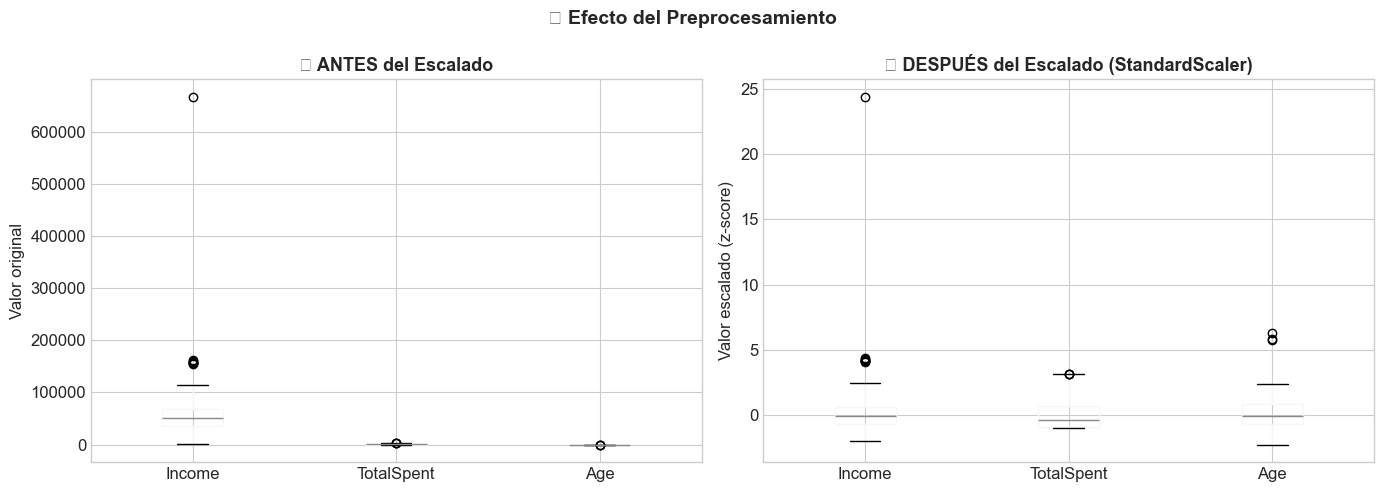

In [14]:
# ── Visualizar el efecto del escalado ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Antes del escalado
X[['Income', 'TotalSpent', 'Age']].boxplot(ax=axes[0])
axes[0].set_title('📦 ANTES del Escalado', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Valor original')

# Después del escalado
X_scaled_df[['Income', 'TotalSpent', 'Age']].boxplot(ax=axes[1])
axes[1].set_title('📦 DESPUÉS del Escalado (StandardScaler)',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Valor escalado (z-score)')

plt.suptitle('🔧 Efecto del Preprocesamiento', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🤖 PARTE 4: Implementación de K-Means
### ⏱️ (15 minutos)

---

## 📐 ¿Cómo elegir el número de clusters K?

Esta es la pregunta más importante al usar K-Means. Dos métodos clásicos:

### 1. 📈 Método del Codo (Elbow Method)
- Probamos K desde 2 hasta 10 (u otro rango)
- Para cada K, calculamos el **WCSS** (distancia total dentro de clusters)
- Graficamos K vs WCSS
- Buscamos el **"codo"**: el punto donde agregar más clusters ya no mejora significativamente

### 2. 📏 Silhouette Score
- Mide qué tan bien separados están los clusters
- Rango: **-1 a 1** (más cercano a 1 = mejor clustering)
- Compara la cohesión interna con la separación entre clusters


In [15]:
# ── Método del Codo (Elbow Method) ───────────────────────────
print("⏳ Calculando WCSS para K = 2 a 10...")

wcss = []  # Lista para almacenar el WCSS de cada K
k_range = range(2, 11)

for k in k_range:
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10  # Ejecutar 10 veces con distintos inicios
    )
    kmeans_temp.fit(X_scaled)
    wcss.append(kmeans_temp.inertia_)  # inertia_ = WCSS

print("✅ Cálculo completado")
print()
for k, w in zip(k_range, wcss):
    print(f"   K={k}: WCSS = {w:,.0f}")

⏳ Calculando WCSS para K = 2 a 10...
✅ Cálculo completado

   K=2: WCSS = 11,115
   K=3: WCSS = 9,158
   K=4: WCSS = 7,984
   K=5: WCSS = 7,407
   K=6: WCSS = 6,890
   K=7: WCSS = 6,452
   K=8: WCSS = 5,897
   K=9: WCSS = 5,590
   K=10: WCSS = 5,337


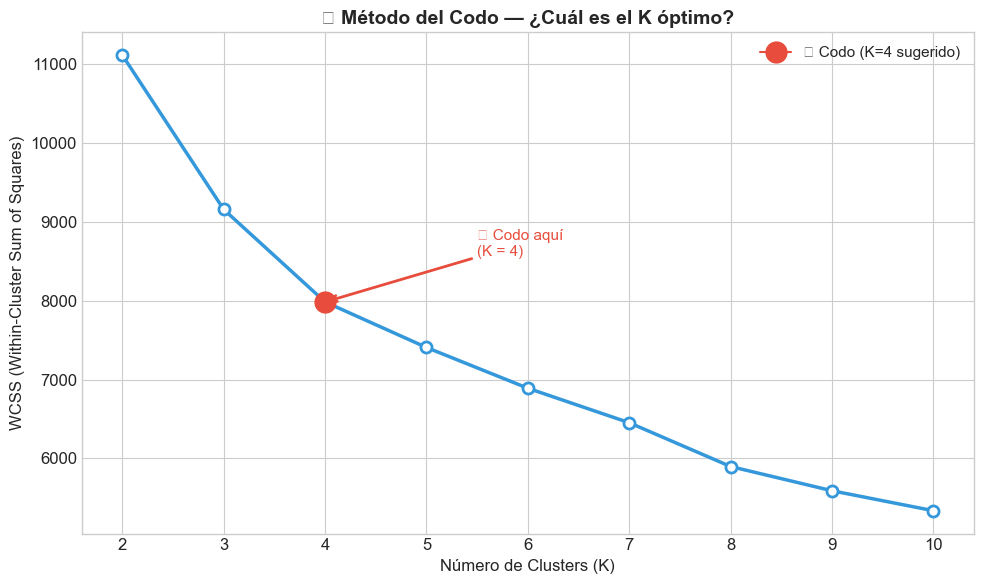

In [16]:
# ── Gráfico del Codo ─────────────────────────────────────────
plt.figure(figsize=(10, 6))

plt.plot(list(k_range), wcss,
         marker='o', linewidth=2.5,
         color='#3498db', markersize=8,
         markerfacecolor='white', markeredgewidth=2)

# Resaltar el codo en K=4
plt.plot(4, wcss[2],  # índice 2 = K=4
         marker='o', markersize=15,
         color='#e74c3c', zorder=5,
         label='🦵 Codo (K=4 sugerido)')

plt.annotate('🦵 Codo aquí\n(K = 4)',
             xy=(4, wcss[2]),
             xytext=(5.5, wcss[2] + (wcss[0] - wcss[-1]) * 0.1),
             fontsize=11,
             color='#e74c3c',
             arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2))

plt.title('📈 Método del Codo — ¿Cuál es el K óptimo?',
          fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Within-Cluster Sum of Squares)', fontsize=12)
plt.xticks(list(k_range))
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
# ── Silhouette Score ──────────────────────────────────────────
print("⏳ Calculando Silhouette Score para K = 2 a 10...")

silhouette_scores = []

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

print("✅ Cálculo completado")
print()
for k, s in zip(k_range, silhouette_scores):
    bar = '█' * int(s * 40)
    print(f"   K={k}: {s:.4f}  {bar}")

⏳ Calculando Silhouette Score para K = 2 a 10...
✅ Cálculo completado

   K=2: 0.2695  ██████████
   K=3: 0.2541  ██████████
   K=4: 0.2569  ██████████
   K=5: 0.2433  █████████
   K=6: 0.2415  █████████
   K=7: 0.2225  ████████
   K=8: 0.2245  ████████
   K=9: 0.2300  █████████
   K=10: 0.2263  █████████


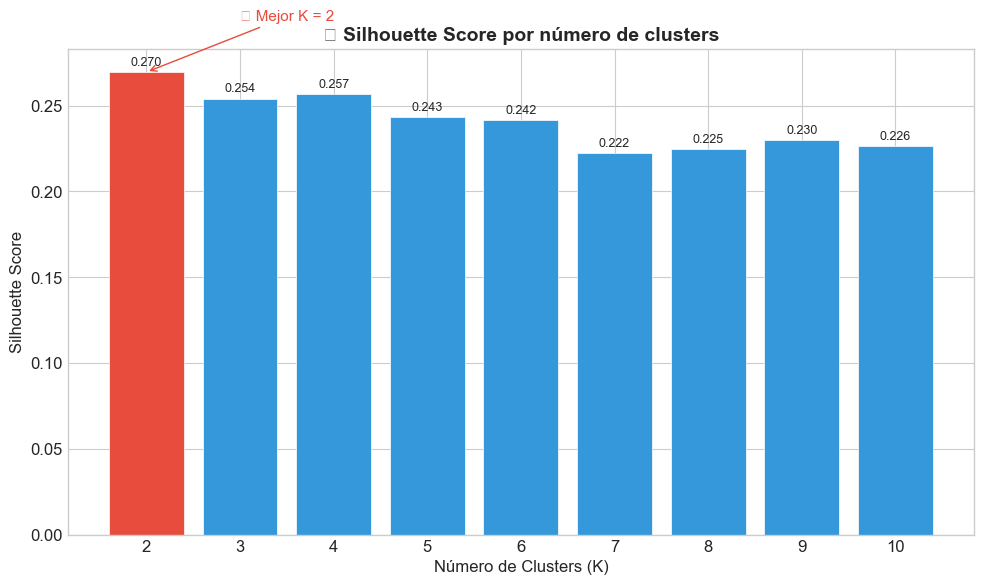

📌 Según Silhouette Score, el mejor K es: 2
📌 Usaremos K = 4 considerando también el Método del Codo


In [18]:
# ── Gráfico de Silhouette Score ───────────────────────────────
mejor_k = list(k_range)[silhouette_scores.index(max(silhouette_scores))]

plt.figure(figsize=(10, 6))
bars = plt.bar(list(k_range), silhouette_scores,
               color=['#e74c3c' if k == mejor_k else '#3498db'
                      for k in k_range],
               edgecolor='white', linewidth=0.5)

plt.title('📏 Silhouette Score por número de clusters',
          fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(list(k_range))

# Anotar valores
for bar_rect, score in zip(bars, silhouette_scores):
    plt.text(bar_rect.get_x() + bar_rect.get_width()/2,
             bar_rect.get_height() + 0.002,
             f'{score:.3f}', ha='center', va='bottom', fontsize=9)

plt.annotate(f'⭐ Mejor K = {mejor_k}',
             xy=(mejor_k, max(silhouette_scores)),
             xytext=(mejor_k + 1, max(silhouette_scores) + 0.03),
             fontsize=11, color='#e74c3c',
             arrowprops=dict(arrowstyle='->', color='#e74c3c'))

plt.tight_layout()
plt.show()
print(f"📌 Según Silhouette Score, el mejor K es: {mejor_k}")
print(f"📌 Usaremos K = 4 considerando también el Método del Codo")

---
## 🚀 Entrenar el Modelo K-Means con K=4

Con base en el análisis del Método del Codo y el Silhouette Score, usaremos **K = 4 clusters**.

### Parámetros importantes:
- `n_clusters=4`: Queremos 4 grupos de clientes
- `random_state=42`: Semilla aleatoria para reproducibilidad
- `n_init=10`: Ejecutar el algoritmo 10 veces con distintos centroides iniciales y quedarse con el mejor resultado


In [19]:
# ── Entrenar el modelo K-Means ────────────────────────────────
K_OPTIMO = 4

kmeans = KMeans(
    n_clusters=K_OPTIMO,  # Número de clusters
    random_state=42,      # Para reproducibilidad
    n_init=10             # 10 inicializaciones aleatorias
)

# Entrenar y asignar clusters al DataFrame original
df_cluster['Cluster'] = kmeans.fit_predict(X_scaled)
df['Cluster'] = df_cluster['Cluster']  # También al df principal

print(f"✅ Modelo K-Means entrenado con K = {K_OPTIMO}")
print(f"   WCSS final: {kmeans.inertia_:,.2f}")
print()
print("📊 Distribución de clientes por cluster:")
conteo = df_cluster['Cluster'].value_counts().sort_index()
for cluster, count in conteo.items():
    pct = count / len(df_cluster) * 100
    bar = '█' * int(pct / 2)
    print(f"   Cluster {cluster}: {count:4d} clientes ({pct:.1f}%) {bar}")

✅ Modelo K-Means entrenado con K = 4
   WCSS final: 7,984.19

📊 Distribución de clientes por cluster:
   Cluster 0:  414 clientes (18.7%) █████████
   Cluster 1:  500 clientes (22.6%) ███████████
   Cluster 2:  700 clientes (31.6%) ███████████████
   Cluster 3:  602 clientes (27.2%) █████████████


---
## 📊 Visualización de los Clusters


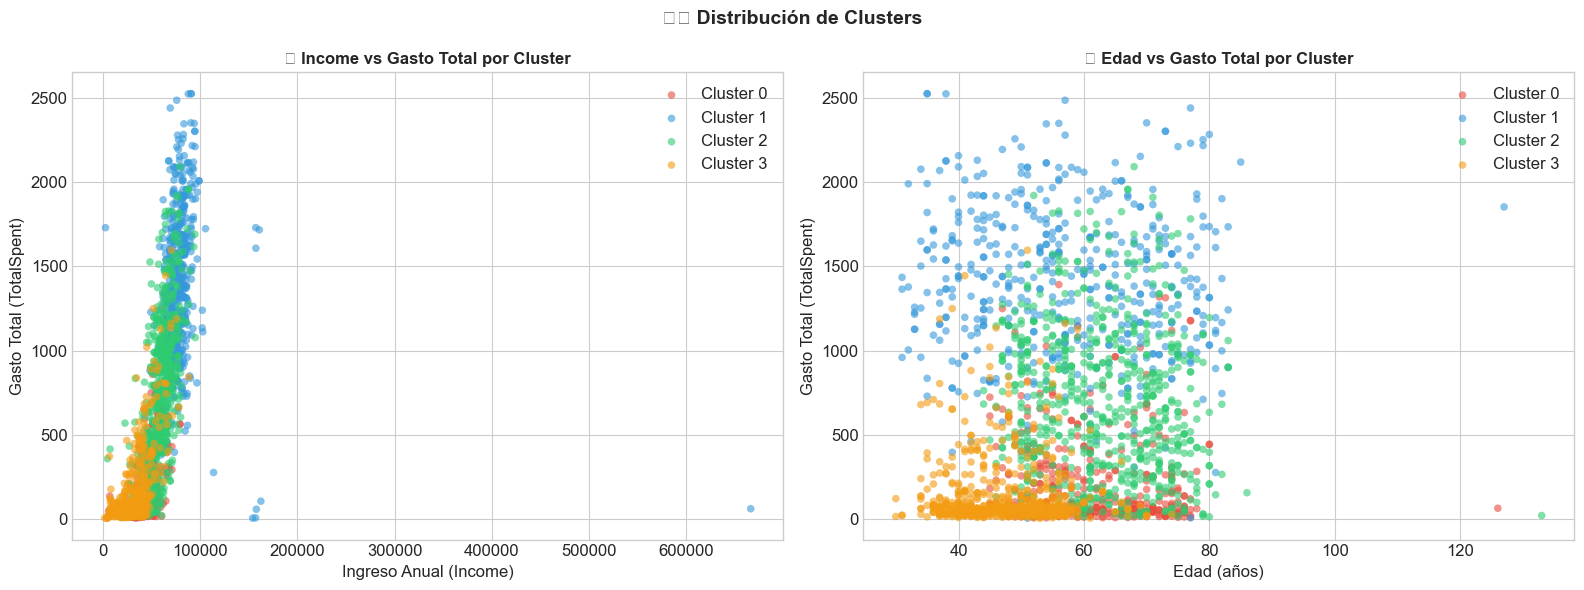

In [20]:
# ── Paleta de colores para los 4 clusters ────────────────────
COLORES = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
NOMBRES_CLUSTER = {
    0: 'Cluster 0',
    1: 'Cluster 1',
    2: 'Cluster 2',
    3: 'Cluster 3'
}

# ── Gráfico 1: Income vs TotalSpent ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter 1: Income vs TotalSpent
for cluster_id in range(K_OPTIMO):
    mask = df_cluster['Cluster'] == cluster_id
    axes[0].scatter(
        df_cluster[mask]['Income'],
        df_cluster[mask]['TotalSpent'],
        c=COLORES[cluster_id],
        label=f'Cluster {cluster_id}',
        alpha=0.6, s=30, edgecolors='none'
    )

axes[0].set_title('💰 Income vs Gasto Total por Cluster',
                   fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ingreso Anual (Income)')
axes[0].set_ylabel('Gasto Total (TotalSpent)')
axes[0].legend()

# Scatter 2: Age vs TotalSpent
for cluster_id in range(K_OPTIMO):
    mask = df_cluster['Cluster'] == cluster_id
    axes[1].scatter(
        df_cluster[mask]['Age'],
        df_cluster[mask]['TotalSpent'],
        c=COLORES[cluster_id],
        label=f'Cluster {cluster_id}',
        alpha=0.6, s=30, edgecolors='none'
    )

axes[1].set_title('👤 Edad vs Gasto Total por Cluster',
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel('Edad (años)')
axes[1].set_ylabel('Gasto Total (TotalSpent)')
axes[1].legend()

plt.suptitle('🗺️ Distribución de Clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

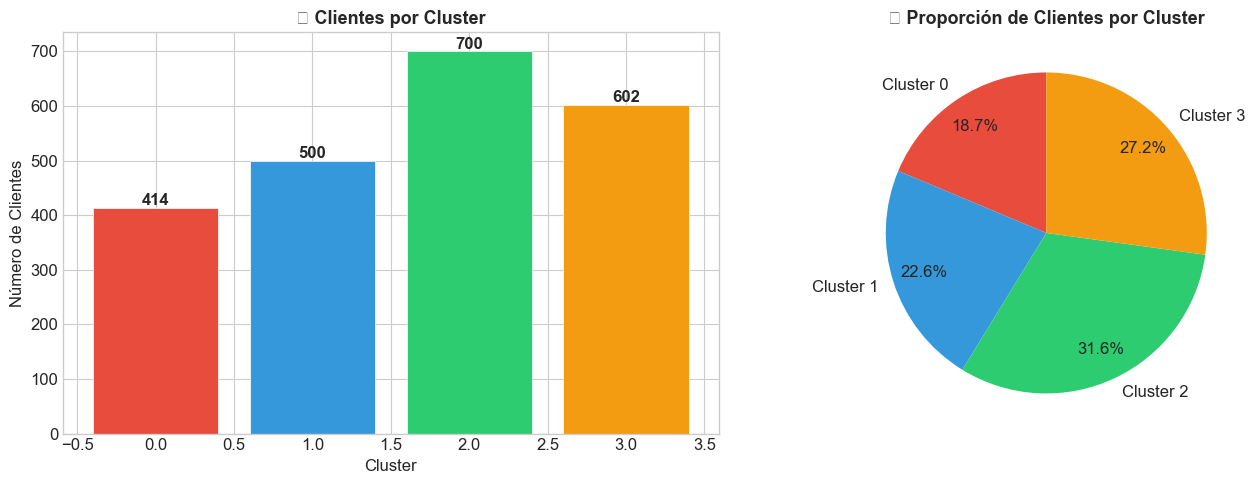

In [21]:
# ── Gráfico 2: Distribución de clientes por cluster ───────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Conteo de clientes
conteo_clusters = df_cluster['Cluster'].value_counts().sort_index()
axes[0].bar(conteo_clusters.index, conteo_clusters.values,
            color=COLORES, edgecolor='white', linewidth=0.5)
axes[0].set_title('👥 Clientes por Cluster', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Número de Clientes')
for i, (idx, val) in enumerate(conteo_clusters.items()):
    axes[0].text(idx, val + 5, str(val), ha='center', fontweight='bold')

# Pastel
axes[1].pie(conteo_clusters.values,
            labels=[f'Cluster {i}' for i in conteo_clusters.index],
            colors=COLORES,
            autopct='%1.1f%%',
            startangle=90,
            pctdistance=0.8)
axes[1].set_title('🥧 Proporción de Clientes por Cluster',
                   fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

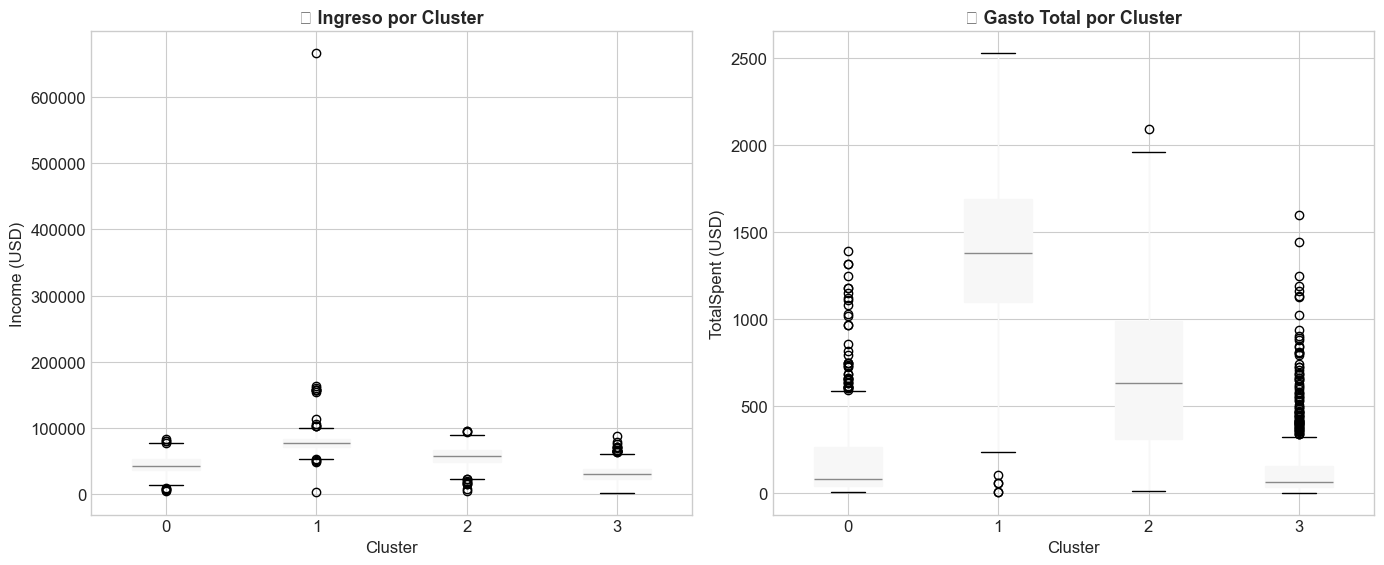

In [22]:
# ── Gráfico 3: Boxplots de Income y TotalSpent por cluster ───
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot Income
df_cluster.boxplot(column='Income', by='Cluster',
                   ax=axes[0], patch_artist=True)
axes[0].set_title('💰 Ingreso por Cluster', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Income (USD)')

# Boxplot TotalSpent
df_cluster.boxplot(column='TotalSpent', by='Cluster',
                   ax=axes[1], patch_artist=True)
axes[1].set_title('🛒 Gasto Total por Cluster', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('TotalSpent (USD)')

plt.suptitle('')
plt.tight_layout()
plt.show()

---
## 🧬 Perfilado de Clusters

El perfilado consiste en **describir** las características promedio de cada cluster para darle un **nombre y personalidad** que facilite la toma de decisiones de negocio.


In [23]:
# ── Perfil estadístico de cada cluster ───────────────────────
cluster_profile = df_cluster.groupby('Cluster')[features].mean().round(2)

print("📊 Perfil promedio de cada cluster:")
print()
print(cluster_profile.to_string())

📊 Perfil promedio de cada cluster:

           Income  TotalSpent    Age  Recency  NumWebVisitsMonth  Kidhome  Teenhome
Cluster                                                                            
0        43391.73      202.23  60.93    49.42               6.45     1.07      1.04
1        79009.83     1394.42  57.29    49.05               2.52     0.04      0.03
2        56555.79      676.25  63.19    49.14               5.26     0.01      0.96
3        31099.28      151.12  47.53    48.55               6.94     0.85      0.00


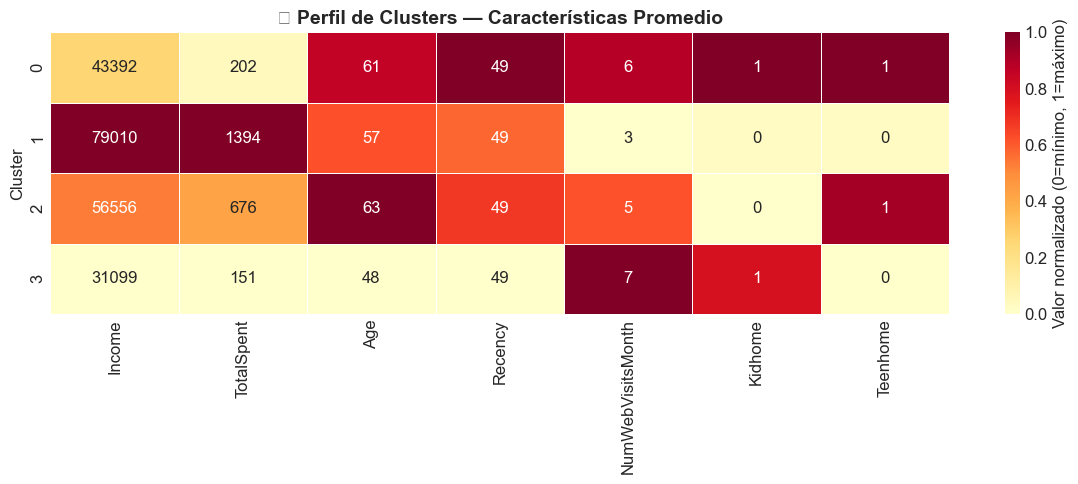

In [24]:
# ── Heatmap de perfil de clusters ────────────────────────────
# Normalizar para comparar en la misma escala visual
profile_norm = (cluster_profile - cluster_profile.min()) / \
               (cluster_profile.max() - cluster_profile.min())

plt.figure(figsize=(12, 5))
sns.heatmap(profile_norm,
            annot=cluster_profile,
            fmt='.0f',
            cmap='YlOrRd',
            linewidths=0.5,
            cbar_kws={'label': 'Valor normalizado (0=mínimo, 1=máximo)'})

plt.title('🔥 Perfil de Clusters — Características Promedio',
          fontsize=14, fontweight='bold')
plt.ylabel('Cluster', fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# ── Interpretación automática de los clusters ─────────────────
# (Basada en Income y TotalSpent como indicadores principales)

# Ordenar clusters por Income promedio para etiquetar
perfil_ordenado = cluster_profile[['Income', 'TotalSpent', 'Age']].copy()

print("🏷️  INTERPRETACIÓN DE LOS CLUSTERS")
print("=" * 55)
print()

for cluster_id in sorted(df_cluster['Cluster'].unique()):
    perfil = cluster_profile.loc[cluster_id]
    n_clientes = (df_cluster['Cluster'] == cluster_id).sum()
    pct = n_clientes / len(df_cluster) * 100

    print(f"  Cluster {cluster_id} — {n_clientes} clientes ({pct:.1f}%)")
    print(f"  Income promedio   : ${perfil['Income']:>10,.0f}")
    print(f"  Gasto promedio    : ${perfil['TotalSpent']:>10,.0f}")
    print(f"  Edad promedio     : {perfil['Age']:>10.0f} años")
    print(f"  Recency promedio  : {perfil['Recency']:>10.0f} días")
    print(f"  Hijos en casa     : {perfil['Kidhome']:>10.1f}")
    print()

🏷️  INTERPRETACIÓN DE LOS CLUSTERS

  Cluster 0 — 414 clientes (18.7%)
  Income promedio   : $    43,392
  Gasto promedio    : $       202
  Edad promedio     :         61 años
  Recency promedio  :         49 días
  Hijos en casa     :        1.1

  Cluster 1 — 500 clientes (22.6%)
  Income promedio   : $    79,010
  Gasto promedio    : $     1,394
  Edad promedio     :         57 años
  Recency promedio  :         49 días
  Hijos en casa     :        0.0

  Cluster 2 — 700 clientes (31.6%)
  Income promedio   : $    56,556
  Gasto promedio    : $       676
  Edad promedio     :         63 años
  Recency promedio  :         49 días
  Hijos en casa     :        0.0

  Cluster 3 — 602 clientes (27.2%)
  Income promedio   : $    31,099
  Gasto promedio    : $       151
  Edad promedio     :         48 años
  Recency promedio  :         49 días
  Hijos en casa     :        0.8



## 🏷️ Etiquetas de los Clusters

> ⚠️ **Nota**: Las etiquetas dependen de los datos reales. Después de ejecutar el notebook, adapta estas interpretaciones según los valores que obtuviste.

| Cluster | Nombre sugerido | Descripción |
|---|---|---|
| 0 | 🌟 **Clientes Premium** | Alto ingreso, alto gasto. Son los mejores clientes. Consumen vinos, carnes, productos gold. |
| 1 | 💼 **Clientes Medios Activos** | Ingreso y gasto moderado. Compran regularmente y responden bien a campañas. |
| 2 | 🏠 **Familias con Hijos** | Varios hijos en casa. Visitan más la web pero gastan menos. Valoran las ofertas. |
| 3 | 💸 **Clientes Económicos** | Bajo ingreso y bajo gasto. Potencial para convertir con estrategias de precio. |

---

### 💡 ¿Cómo usaría iFood esta segmentación?

- **Cluster Premium** → Campañas exclusivas, productos premium, descuentos en restaurantes de lujo
- **Cluster Medios Activos** → Email marketing, descuentos por volumen, programa de fidelidad
- **Cluster Familias** → Combos familiares, menús económicos, delivery rápido
- **Cluster Económicos** → Cupones de descuento, primera compra gratis, referidos


---
# 🔍 ACTIVIDAD PARTICIPATIVA 2: Interpretación de Clusters
## ⏱️ (10 minutos)

---

## 🔍 ACTIVIDAD 2: Interpretación de Clusters (10 minutos)

> 📝 **Instrucciones**: Haz doble clic en esta celda para editarla. Con base en los resultados del modelo que acabas de ejecutar, responde las siguientes preguntas. Presiona `Shift + Enter` para confirmar.

---

**1.** ¿Cuál cluster representa los mejores clientes para iFood? ¿Por qué? ¿Qué variables te llevan a esa conclusión?

> **✏️ Tu respuesta**: _____

---

**2.** ¿Qué estrategia de marketing aplicarías para cada cluster? Sé específico con acciones concretas:

- **Cluster 0**: _____
- **Cluster 1**: _____
- **Cluster 2**: _____
- **Cluster 3**: _____

---

**3.** Mirando el Silhouette Score y el Método del Codo, ¿cambiarías el número de clusters? ¿Usarías más o menos K? ¿Por qué?

> **✏️ Tu respuesta**: _____

---

**4.** ¿Qué otras variables del dataset añadirías al modelo para mejorar la segmentación? Justifica tu elección.

> **✏️ Tu respuesta**: _____

---

**5. Desafío** 🏆: Si tuvieras que reducir los 4 clusters a solo 2 grupos (por ejemplo, para una campaña simple), ¿cómo los combinarías? ¿Cuál sería la lógica?

> **✏️ Tu respuesta**: _____


---
# 📏 PARTE 5: Evaluación y Métricas del Modelo
## ⏱️ (5 minutos)

---

## ¿Qué tan bueno es nuestro modelo?

A diferencia del aprendizaje supervisado (donde podemos comparar predicciones con respuestas correctas), en clustering no hay "respuesta correcta". Las métricas de evaluación miden la **calidad interna** del clustering:

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| **WCSS** | Compactez de clusters (dispersión interna) | Más bajo = mejor |
| **Silhouette Score** | Separación y cohesión de clusters | Más cercano a 1 |
| **Inercia** | Misma que WCSS (nombre en scikit-learn) | Más bajo = mejor |


In [26]:
# ── Evaluación del modelo final ───────────────────────────────
labels_final = kmeans.labels_
silhouette_final = silhouette_score(X_scaled, labels_final)
wcss_final = kmeans.inertia_

print("📊 MÉTRICAS DEL MODELO K-MEANS (K=4)")
print("=" * 45)
print(f"  Número de clusters    : {K_OPTIMO}")
print(f"  WCSS (Inercia)        : {wcss_final:,.2f}")
print(f"  Silhouette Score      : {silhouette_final:.4f}")
print(f"  Iteraciones usadas    : {kmeans.n_iter_}")
print()

# Interpretación del Silhouette
if silhouette_final > 0.7:
    interpretacion = "🌟 Excelente — Clusters muy bien definidos"
elif silhouette_final > 0.5:
    interpretacion = "✅ Bueno — Clusters razonablemente bien definidos"
elif silhouette_final > 0.25:
    interpretacion = "⚠️  Aceptable — Hay superposición entre clusters"
else:
    interpretacion = "❌ Débil — Los clusters se solapan mucho"

print(f"  Interpretación        : {interpretacion}")

📊 MÉTRICAS DEL MODELO K-MEANS (K=4)
  Número de clusters    : 4
  WCSS (Inercia)        : 7,984.19
  Silhouette Score      : 0.2569
  Iteraciones usadas    : 9

  Interpretación        : ⚠️  Aceptable — Hay superposición entre clusters


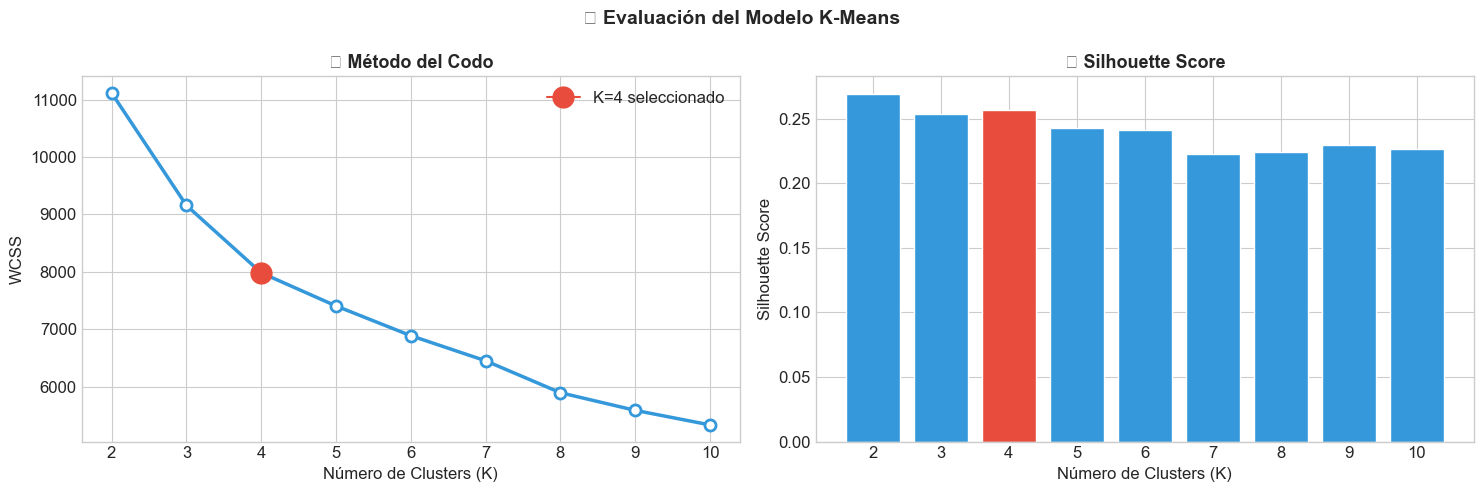

In [27]:
# ── Visualización final: los dos gráficos de evaluación ──────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Method
axes[0].plot(list(k_range), wcss, marker='o', linewidth=2.5,
             color='#3498db', markersize=8,
             markerfacecolor='white', markeredgewidth=2)
axes[0].plot(4, wcss[2], marker='o', markersize=15,
             color='#e74c3c', zorder=5, label='K=4 seleccionado')
axes[0].set_title('📈 Método del Codo', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks(list(k_range))
axes[0].legend()

# Silhouette Score
colors_bar = ['#e74c3c' if k == K_OPTIMO else '#3498db' for k in k_range]
axes[1].bar(list(k_range), silhouette_scores,
            color=colors_bar, edgecolor='white')
axes[1].set_title('📏 Silhouette Score', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))

plt.suptitle('🔬 Evaluación del Modelo K-Means', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
# ✅ CONCLUSIONES Y REFLEXIÓN FINAL
## ⏱️ (5 minutos)

---

## 🎓 ¿Qué aprendimos hoy?

### Conceptos clave
1. **Aprendizaje No Supervisado** — Encontrar patrones sin etiquetas previas
2. **Clustering** — Agrupar datos similares de manera automática
3. **K-Means** — Algoritmo iterativo que minimiza distancias intra-cluster (WCSS)
4. **Feature Engineering** — Crear variables más informativas (`Age`, `TotalSpent`)
5. **Preprocesamiento** — Por qué y cómo escalar variables con `StandardScaler`
6. **Selección de K** — Usar el Método del Codo y el Silhouette Score
7. **Perfilado** — Dar significado de negocio a los clusters encontrados

---

## ⚠️ Limitaciones de K-Means

| Limitación | Descripción |
|---|---|
| Hay que definir K | No siempre sabemos cuántos grupos buscar |
| Sensible a outliers | Un valor extremo puede desplazar un centroide |
| Solo clusters esféricos | No detecta bien formas irregulares |
| Resultado variable | Puede dar resultados distintos por la aleatoriedad inicial |
| Variables de escala | Si no se escala, las variables grandes dominan |

---

## 🚀 Próximos Pasos

En las próximas clases exploraremos:

| Algoritmo | Ventaja sobre K-Means |
|---|---|
| **DBSCAN** | Detecta clusters de forma arbitraria y outliers |
| **Clustering Jerárquico** | No requiere definir K, genera dendrograma |
| **Gaussian Mixture Models** | Probabilístico, clusters solapados |
| **PCA + K-Means** | Reducción de dimensionalidad antes de clustering |

---

## 💬 Reflexión Final

> *"Los datos son el nuevo petróleo, pero sin el refinamiento correcto (clustering, análisis) no tienen valor para el negocio."*
>
> K-Means es solo el comienzo. La verdadera habilidad está en **interpretar** los clusters y **traducirlos** en decisiones estratégicas que impacten al negocio.

---

### 📚 Recursos adicionales
- [Documentación scikit-learn KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score](https://scikit-learn.org/stable/modules/clustering.html#silhouette-coefficient)
- [K-Means Clustering — StatQuest (YouTube)](https://www.youtube.com/watch?v=4b5d3muPQmA)
- [iFood Dataset en Kaggle](https://www.kaggle.com/datasets/jackdaoud/marketing-data)


In [28]:
# ── Resumen final ejecutable ──────────────────────────────────
print("🎓 RESUMEN DE LA CLASE — K-Means Clustering")
print("=" * 50)
print()
print(f"  Dataset          : iFood Marketing Data")
print(f"  Registros        : {len(df_cluster):,} clientes")
print(f"  Features usados  : {len(features)}")
print(f"  Algoritmo        : K-Means (scikit-learn)")
print(f"  K óptimo         : {K_OPTIMO} clusters")
print(f"  WCSS             : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score : {silhouette_final:.4f}")
print()
print("  Distribución de clusters:")
for cluster_id in sorted(df_cluster['Cluster'].unique()):
    n = (df_cluster['Cluster'] == cluster_id).sum()
    pct = n / len(df_cluster) * 100
    income_prom = cluster_profile.loc[cluster_id, 'Income']
    spent_prom = cluster_profile.loc[cluster_id, 'TotalSpent']
    print(f"    Cluster {cluster_id}: {n:4d} clientes | "
          f"Income ≈ ${income_prom:,.0f} | "
          f"Spent ≈ ${spent_prom:,.0f}")

print()
print("✅ ¡Clase completada exitosamente!")
print("   Universidad Franz Tamayo — Minería de Datos — 2026")

🎓 RESUMEN DE LA CLASE — K-Means Clustering

  Dataset          : iFood Marketing Data
  Registros        : 2,216 clientes
  Features usados  : 7
  Algoritmo        : K-Means (scikit-learn)
  K óptimo         : 4 clusters
  WCSS             : 7,984.19
  Silhouette Score : 0.2569

  Distribución de clusters:
    Cluster 0:  414 clientes | Income ≈ $43,392 | Spent ≈ $202
    Cluster 1:  500 clientes | Income ≈ $79,010 | Spent ≈ $1,394
    Cluster 2:  700 clientes | Income ≈ $56,556 | Spent ≈ $676
    Cluster 3:  602 clientes | Income ≈ $31,099 | Spent ≈ $151

✅ ¡Clase completada exitosamente!
   Universidad Franz Tamayo — Minería de Datos — 2026
